# Student Performance: Beyond the Grades

A final grade tells us how a student performed, but not the whole story behind it.

In this project, we analyze the Student Performance dataset, which contains academic, demographic, family, and school-related information about students from two Portuguese secondary schools.

Focusing on Portuguese language grades, we explore patterns in students' final performance and consider the limitations of using these data to judge a student's ability or potential.

## Research Questions and Exploratory Hypotheses

Our main research question is:

What factors are associated with students' final grades, and which factors should we refuse to use when evaluating students?

To explore this question, we investigate the following hypotheses:

H1: Higher previous grades (G1 and G2) are associated with higher final grades (G3).

H2: More study time (studytime) is associated with higher final grades.

H3: Students with previous class failures (failures) tend to have lower final grades than students without previous failures.

H4: More absences (absences) may be associated with lower final grades.

H5: Final grade distributions may differ between students receiving and not receiving extra school support (schoolsup).

These exploratory hypotheses guide our analysis. We interpret the observed relationships carefully, recognizing that association does not necessarily imply causation.

### 0. Setting Up the Environment

We connect Google Drive to Google Colab and define the paths to our project folders. The `data` folder stores the dataset, while the `figures` folder is used to save visualizations generated during the analysis.

In [1]:
# --- Setup: mount Drive and define paths ---
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Student-Performance")
DATA = ROOT / "data"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

print("Data files:", [f.name for f in DATA.iterdir()])

Mounted at /content/drive
Data files: ['student-por.csv']


### 1. Loading the Dataset

We load the student performance dataset into a Pandas DataFrame and measure the time required to read the file. We then check its dimensions to understand how many rows and columns it contains.

In [2]:
import time
import pandas as pd

start = time.time()

df_raw = pd.read_csv(DATA / "student-por.csv", sep=";")

print(f"Loaded in {time.time() - start:.1f} seconds")
print("Shape (rows, columns):", df_raw.shape)

Loaded in 0.6 seconds
Shape (rows, columns): (649, 33)


### 2. Initial Data Inspection
Before analyzing student performance, we inspect the dataset's structure, column names, data types, and sample records. We also check for missing values and duplicate rows to assess data quality and identify potential issues that may require further investigation.

In [3]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nDataset information:")
df_raw.info()


Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardi

**Key Observations:**
- The dataset contains **649 students and 33 columns**.
- Variables are divided into **16 numerical and 17 categorical variables**, which require different approaches to analysis.
- No missing values were detected during the initial inspection, so no missing-value treatment is needed at this stage.

In [4]:
display(df_raw.head(10))


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,6,12,12,13
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,13,12,13
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,2,10,13,13
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,15,16,17
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,12,12,13



- The dataset contains demographic, family, lifestyle, and academic information.
- Students in these first 10 rows are aged 15–18.
- Grades (`G1`, `G2`, `G3`) and absences vary between students.
- These rows provide an additional sample of the dataset, but no general conclusions should be drawn from these observations alone.

In [5]:
display(df_raw.tail(10))

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
639,MS,M,19,R,GT3,T,1,1,other,services,...,4,3,2,1,3,5,0,5,8,0
640,MS,M,18,R,GT3,T,4,2,other,other,...,5,4,3,4,3,3,0,7,7,0
641,MS,F,18,R,GT3,T,2,2,at_home,other,...,5,3,3,1,3,4,0,14,17,15
642,MS,F,17,U,GT3,T,4,3,teacher,other,...,5,5,4,1,1,1,0,6,9,11
643,MS,F,18,R,GT3,T,4,4,teacher,at_home,...,4,4,3,2,2,5,4,7,9,10
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10
648,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,4,10,11,11



- The last 10 rows belong to students from school **MS**, aged 17–19.
- Final grades (`G3`) vary from **0 to 16** in these rows.
- Some students have zero absences but still have low or zero final grades.
- These observations show that absences alone do not explain academic performance; further analysis is needed.

In [6]:
print("Duplicate rows:", df_raw.duplicated().sum())

Duplicate rows: 0



- No duplicate rows were found, so all 649 records are unique at the row level.

### 3. Descriptive Statistics

After checking the dataset's structure and data quality, we examine descriptive statistics to better understand students' academic performance. We focus on the grades `G1`, `G2`, and `G3` to explore their averages, ranges, and variability. This provides a foundation for investigating factors associated with students' final grades.

In [7]:
display(df_raw[["G1", "G2", "G3"]].describe())

,G1,G2,G3
count,649.000000,649.000000,649.000000
mean,11.399076,11.570108,11.906009
std,2.745265,2.913639,3.230656
min,0.000000,0.000000,0.000000
25%,10.000000,10.000000,10.000000
50%,11.000000,11.000000,12.000000
75%,13.000000,13.000000,14.000000
max,19.000000,19.000000,19.000000





- The average grade increases slightly from 11.40 in G1 to 11.91 in G3, suggesting a small increase in overall average performance.
- The median final grade is 12, with the middle 50% of students scoring between 10 and 14.
- Final grades show greater variability than earlier grades, indicating more differences in students' final performance.
- Zero grades appear in all three grade columns and require further investigation.

Overall, these results describe grade patterns but do not explain why students' performance differs.


**Investigating Zero Grades**

Since the minimum grade is 0 in all three grade columns, we examine how many students have zero grades in G1, G2, and G3. This helps us understand how frequent these cases are before deciding how to interpret them.

In [8]:
grades = df_raw[["G1", "G2", "G3"]]

zero_summary = pd.DataFrame({
    "Number of zero grades": (grades == 0).sum(),
    "Percentage (%)": ((grades == 0).mean() * 100).round(2)
})

display(zero_summary)

,Number of zero grades,Percentage (%)
G1,1,0.15
G2,7,1.08
G3,15,2.31




- Zero grades increase from 1 in G1 to 7 in G2 and 15 in G3. Even in G3, zero grades represent only 2.31% of students.
- These cases are relatively uncommon, but their meaning should be investigated before deciding how to handle them.



In [9]:
zero_g3 = df_raw.loc[
    df_raw["G3"] == 0,
    ["school", "sex", "age", "absences",
     "G1", "G2", "failures", "schoolsup"]
]

print("Number of students with G3 = 0:", len(zero_g3))
display(zero_g3)

print("School distribution:")
display(zero_g3["school"].value_counts())

print("Students with G2 = 0:", (zero_g3["G2"] == 0).sum())
print("Students with zero absences:", (zero_g3["absences"] == 0).sum())

Number of students with G3 = 0: 15


,school,sex,age,absences,G1,G2,failures,schoolsup
163,GP,M,18,0,11,9,2,no
440,MS,M,16,0,7,0,0,no
519,MS,M,16,0,8,7,0,no
563,MS,M,17,0,7,0,1,no
567,MS,M,18,0,4,0,1,no
583,MS,F,18,0,8,6,1,no
586,MS,F,17,0,8,8,0,yes
597,MS,F,18,0,9,0,1,no
603,MS,F,18,0,5,0,0,no
605,MS,F,19,0,5,0,1,no


School distribution:


,count
school,
MS,14
GP,1


Students with G2 = 0: 7
Students with zero absences: 15




All 15 students with a final grade of zero have no recorded absences, and 14 attend school MS. Seven also have a zero in G2. These patterns suggest that zero grades deserve further investigation, but the available data do not explain why these grades occurred.

### 4. Exploring Final Grade Distribution

Before investigating factors associated with academic performance, we examine the distribution of final grades (`G3`). This helps us identify the most common grades, understand how grades vary among students, and observe whether very low or high grades are uncommon.

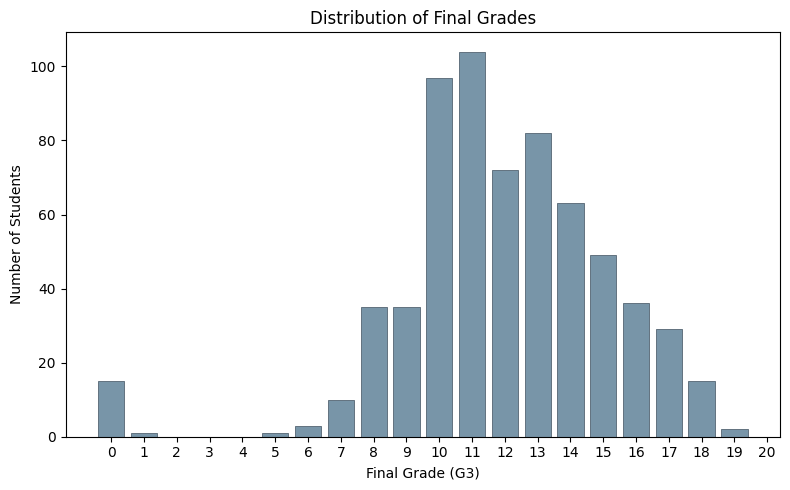

In [10]:
import matplotlib.pyplot as plt

grade_counts = df_raw["G3"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(
    grade_counts.index,
    grade_counts.values,
    color="#7895A8",
    edgecolor="#536471",
    linewidth=0.6
)

plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Grades")
plt.xticks(range(0, 21))
plt.tight_layout()
plt.show()



- **Most frequent grades:** Grades 10 and 11 appear most frequently, indicating that many students achieve results around this range.
- **Grade distribution:** Most results are concentrated around grades 10–14, while the number of students generally decreases at higher grades.
- **Low grades:** Some students receive very low grades, including 0, highlighting cases that may require further investigation.
- **Highest grade:** No students received a grade of 20.

Overall, the graph shows that middle-range grades are more common than very high grades. However, it does not explain why students achieve different results or which factors influence their performance.

5. Exploring Factors Associated with Final Grades

After examining the distribution of final grades, we investigate how academic, study-related, and social factors are associated with students' final performance. Our goal is to identify meaningful patterns while recognizing that associations do not necessarily imply causation.

#### 5.1 Previous Academic Performance

We examine the relationship between previous grades (`G1` and `G2`) and the final grade (`G3`). This helps us understand how earlier academic performance is associated with students' final results.

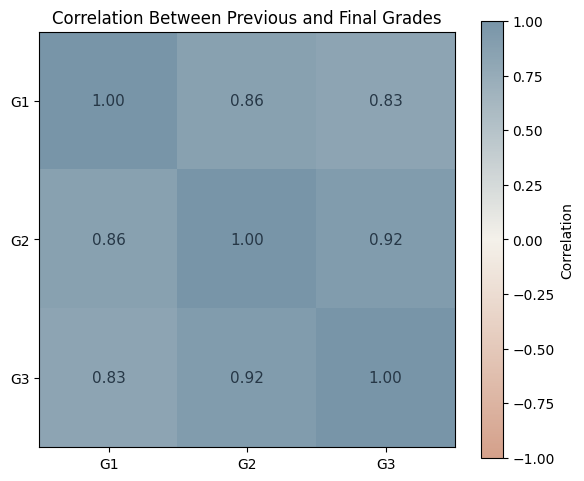

In [11]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Calculate correlations between grades
grades_corr = df_raw[["G1", "G2", "G3"]].corr()

# Soft color palette
soft_corr = LinearSegmentedColormap.from_list(
    "soft_corr",
    ["#D4A08A", "#F4F1EA", "#7895A8"]
)

plt.figure(figsize=(6, 5))

plt.imshow(
    grades_corr,
    cmap=soft_corr,
    vmin=-1,
    vmax=1
)

# Axis labels
plt.xticks(range(3), grades_corr.columns)
plt.yticks(range(3), grades_corr.columns)

# Display correlation values inside each cell
for i in range(3):
    for j in range(3):
        plt.text(
            j,
            i,
            f"{grades_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="#263746",
            fontsize=11
        )

plt.colorbar(label="Correlation")
plt.title("Correlation Between Previous and Final Grades")
plt.tight_layout()

plt.savefig(
    FIGURES / "grades_correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()



- All grades show strong positive correlations, meaning higher grades in one period tend to be associated with higher grades in another.
- `G2` has the strongest correlation with the final grade `G3` (**0.92**), followed by `G1` (**0.83**).


##### Change from G2 to G3

We examine how final grades (`G3`) differ from second-period grades (`G2`) to understand whether students' grades increased, decreased, or remained unchanged.

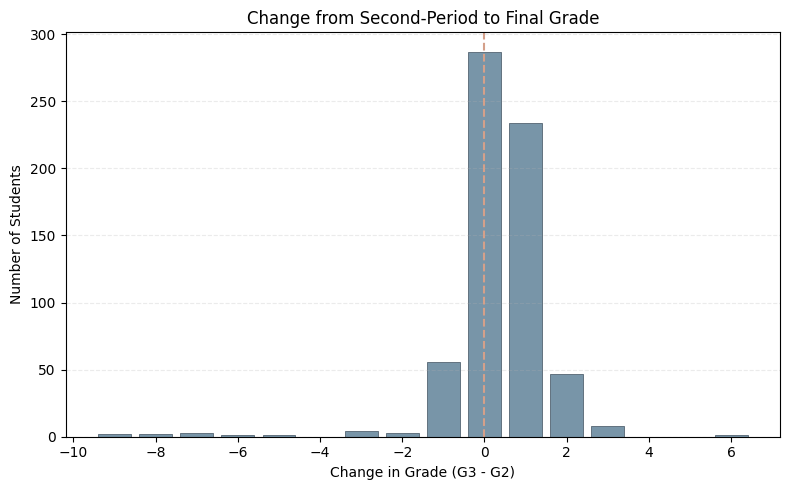

Grades increased: 290
Grades unchanged: 287
Grades decreased: 72
Students within ±1 point of G2: 577 out of 649 (88.9%)


In [12]:
import matplotlib.pyplot as plt

# Calculate the change from G2 to G3
grade_change = df_raw["G3"] - df_raw["G2"]
change_counts = grade_change.value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    change_counts.index,
    change_counts.values,
    color="#7895A8",
    edgecolor="#536471",
    linewidth=0.6
)

plt.axvline(
    0,
    color="#D4A08A",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Change in Grade (G3 - G2)")
plt.ylabel("Number of Students")
plt.title("Change from Second-Period to Final Grade")
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.savefig(
    FIGURES / "grade_change_g2_g3.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Summarize the changes
within_one = grade_change.abs().le(1).sum()

print("Grades increased:", (grade_change > 0).sum())
print("Grades unchanged:", (grade_change == 0).sum())
print("Grades decreased:", (grade_change < 0).sum())
print(
    f"Students within ±1 point of G2: "
    f"{within_one} out of {len(df_raw)} "
    f"({within_one / len(df_raw) * 100:.1f}%)"
)



- **88.9%** of students finished within one point of their second-period grade (`G2`).
- Final grades increased for 290 students, remained unchanged for 287, and decreased for 72.

This suggests that academic performance is generally stable, but previous grades do not determine a student's future potential.

#### 5.2 Study Habits and School Factors

We examine whether study habits and school-related factors are associated with students' final grades. We begin by comparing final grades across different weekly study-time groups to explore potential patterns in academic performance.

We compare the number of students, average final grade, and median final grade across the four study-time categories to identify possible differences in academic performance.


In [13]:
studytime_summary = df_raw.groupby("studytime")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

studytime_summary = studytime_summary.rename(columns={
    "count": "Number of Students",
    "mean": "Average Final Grade",
    "median": "Median Final Grade"
})

display(studytime_summary)

,Number of Students,Average Final Grade,Median Final Grade
studytime,,,
1,212,10.84,11.0
2,305,12.09,12.0
3,97,13.23,13.0
4,35,13.06,13.0



- Students studying less than 2 hours per week have the lowest average final grade (**10.84**).
- The average grade increases with study time, reaching **13.23** for students who study 5–10 hours per week.
- Students studying more than 10 hours have a slightly lower average (**13.06**), but this group contains only 35 students.
- More study time is associated with higher average grades, although this does not prove that study time directly causes better performance.

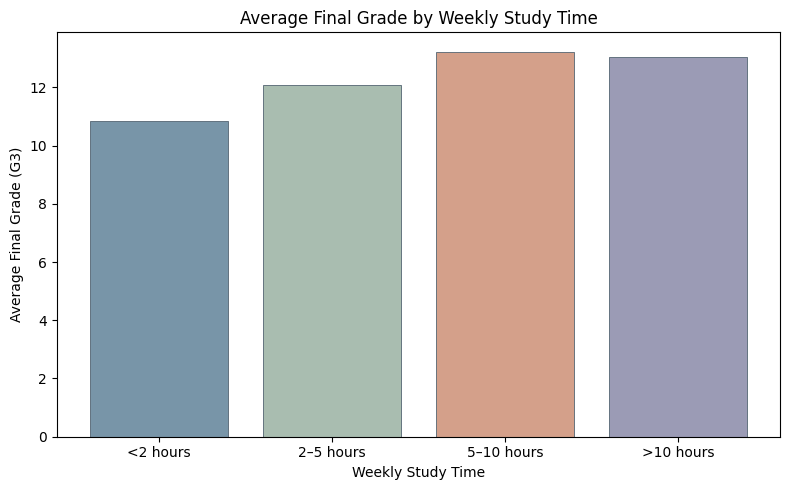

In [14]:
study_labels = {
    1: "<2 hours",
    2: "2–5 hours",
    3: "5–10 hours",
    4: ">10 hours"
}

study_means = df_raw.groupby("studytime")["G3"].mean()

plt.figure(figsize=(8, 5))
colors = ["#7895A8", "#A9BDB0", "#D4A08A", "#9B9BB5"]

plt.bar(
    [study_labels[i] for i in study_means.index],
    study_means.values,
    color=colors[:len(study_means)],
    edgecolor="#536471",
    linewidth=0.6
)

plt.xlabel("Weekly Study Time")
plt.ylabel("Average Final Grade (G3)")
plt.title("Average Final Grade by Weekly Study Time")
plt.tight_layout()
plt.show()



The chart shows that average final grades increase with study time up to the 5–10 hours category, where the average reaches 13.23. For students studying more than 10 hours, the average decreases slightly to 13.06. This suggests a positive association between study time and grades, although the trend is not strictly increasing.

##### Previous Failures and Final Grades

We examine how previous class failures are associated with students' final grades. A box plot allows us to compare grade distributions across failure groups and identify differences in typical performance and variability.

In [15]:
failure_summary = df_raw.groupby("failures")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

failure_summary = failure_summary.rename(columns={
    "count": "Number of Students",
    "mean": "Average Final Grade",
    "median": "Median Final Grade"
})

display(failure_summary)

,Number of Students,Average Final Grade,Median Final Grade
failures,,,
0,549,12.51,12.0
1,70,8.64,10.0
2,16,8.81,9.5
3,14,8.07,8.5


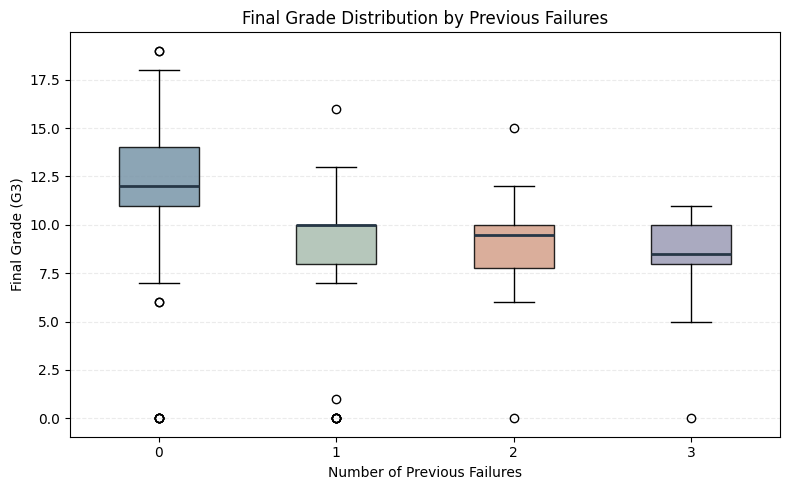

In [16]:
import matplotlib.pyplot as plt

failure_groups = sorted(df_raw["failures"].dropna().unique())

failure_data = [
    df_raw.loc[df_raw["failures"] == group, "G3"].dropna()
    for group in failure_groups
]

colors = ["#7895A8", "#A9BDB0", "#D4A08A", "#9B9BB5"]

plt.figure(figsize=(8, 5))

box = plt.boxplot(
    failure_data,
    patch_artist=True,
    showfliers=True
)

for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

for median in box["medians"]:
    median.set_color("#263746")
    median.set_linewidth(2)

plt.xticks(
    range(1, len(failure_groups) + 1),
    [str(int(group)) for group in failure_groups]
)

plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade (G3)")
plt.title("Final Grade Distribution by Previous Failures")
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()



- Students with no previous failures have the highest average final grade (**12.51**) and a median of **12**.
- Students with previous failures have lower average grades (**8.07–8.81**) and lower medians (**8.5–10**).
- Most students (**549 out of 649**) have no previous failures, while the groups with two and three failures are much smaller (**16 and 14 students**).
- Although the median decreases across the failure groups, the average grades do not decrease steadily as failures increase.

Previous failures are associated with lower final grades, but this does not prove causation. Results for the smaller groups should be interpreted cautiously.

##### Checking the Effect of Zero Final Grades

We compare final grades across previous-failure groups, both with and without students whose final grade is zero. This sensitivity check helps us determine whether zero-grade cases affect our interpretation of the relationship between previous failures and final performance.

In [17]:
# Compare failure groups with and without zero final grades
failure_all = df_raw.groupby("failures")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

failure_nonzero = (
    df_raw[df_raw["G3"] != 0]
    .groupby("failures")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("All students:")
display(failure_all)

print("Excluding students with G3 = 0:")
display(failure_nonzero)

All students:


,count,mean,median
failures,,,
0,549,12.51,12.0
1,70,8.64,10.0
2,16,8.81,9.5
3,14,8.07,8.5


Excluding students with G3 = 0:


,count,mean,median
failures,,,
0,543,12.65,12.0
1,63,9.60,10.0
2,15,9.40,10.0
3,13,8.69,9.0




- Excluding students with `G3 = 0` increases the average final grade in every previous-failure group.
- The largest increase occurs among students with one previous failure, from 8.64 to 9.60.
- Students with no previous failures continue to have the highest average final grade (12.65).
- The main finding remains unchanged: previous failures are associated with lower final grades, although the groups with multiple failures are small.

This comparison shows that zero grades affect the group averages, but the overall pattern remains similar. Since the reasons for zero grades are unknown, these cases should not automatically be removed from the analysis.

##### Absences and Final Grades

We investigate the relationship between school absences and students' final grades (`G3`). Using descriptive statistics and a scatter plot, we examine whether students with more absences tend to achieve different academic results. The goal is to identify patterns in the data without assuming that absences directly cause changes in grades.

In [18]:
# Examine absences and final grades
display(df_raw[["absences", "G3"]].describe().round(2))

correlation = df_raw["absences"].corr(df_raw["G3"])
print(f"Correlation between absences and final grade: {correlation:.2f}")

,absences,G3
count,649.00,649.00
mean,3.66,11.91
std,4.64,3.23
min,0.00,0.00
25%,0.00,10.00
50%,2.00,12.00
75%,6.00,14.00
max,32.00,19.00


Correlation between absences and final grade: -0.09


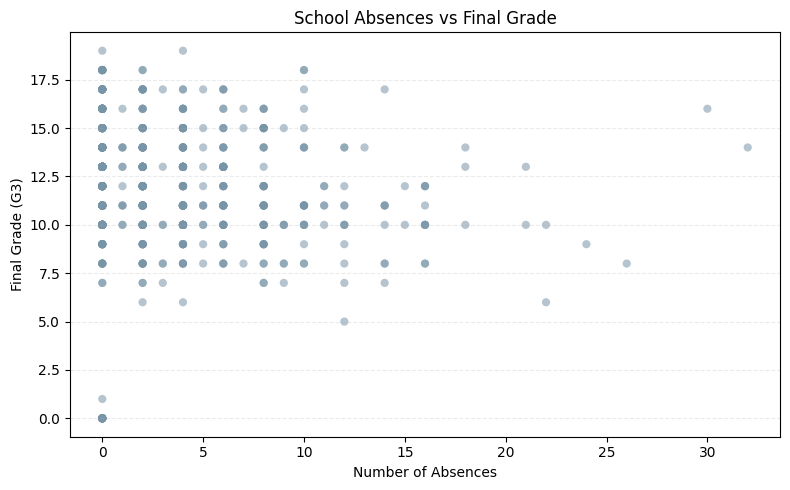

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_raw["absences"],
    df_raw["G3"],
    color="#7895A8",
    alpha=0.55,
    s=35,
    edgecolors="none"
)

plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.title("School Absences vs Final Grade")
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()

To assess whether zero final grades affect the relationship between absences and academic performance, we compare the correlation using all students with the correlation after excluding students with `G3 = 0`. This sensitivity check helps us understand how these cases influence the results.

In [20]:
# Compare the correlation with and without zero final grades
df_no_zero_g3 = df_raw[df_raw["G3"] != 0]

corr_all = df_raw["absences"].corr(df_raw["G3"])
corr_no_zero = df_no_zero_g3["absences"].corr(
    df_no_zero_g3["G3"]
)

print(f"All students (n={len(df_raw)}): {corr_all:.2f}")
print(
    f"Excluding G3 = 0 (n={len(df_no_zero_g3)}): "
    f"{corr_no_zero:.2f}"
)

All students (n=649): -0.09
Excluding G3 = 0 (n=634): -0.20


**Key Findings**

- Students have an average of 3.66 absences, while the median is 2. Most students have 6 or fewer absences, although some have as many as 32.
- The scatter plot shows considerable variation in final grades among students with similar numbers of absences.
- Using all 649 students, the correlation between absences and final grades is very weak and negative (`r = -0.09`).
- Excluding the 15 students with `G3 = 0`, the correlation becomes more negative (`r = -0.20`), but remains weak.
- All 15 students with zero final grades also have zero recorded absences, which affects how we interpret the relationship.

These findings suggest that absences alone do not adequately explain final grades. The zero-grade cases require careful interpretation because the dataset does not explain why these grades occurred.

##### School Support and Final Grades

We examine whether students receiving extra educational support from school have different final grade distributions from those who do not. Comparing these groups helps us explore the relationship between school support and academic performance.

In [21]:
support_summary = df_raw.groupby("schoolsup")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

support_summary = support_summary.rename(columns={
    "count": "Number of Students",
    "mean": "Average Final Grade",
    "median": "Median Final Grade"
})

display(support_summary)

,Number of Students,Average Final Grade,Median Final Grade
schoolsup,,,
no,581,11.98,12.0
yes,68,11.28,11.0



- Most students (**581**) do not receive extra school support, while only **68** receive it.
- Students without extra support have a higher average final grade (**11.98**) than those receiving support (**11.28**).
- The median final grade is 12 for students without support and 11 for those receiving support.

The table shows slightly lower grades among students receiving extra support. However, this does not mean that support lowers grades; these students may already be experiencing academic difficulties.

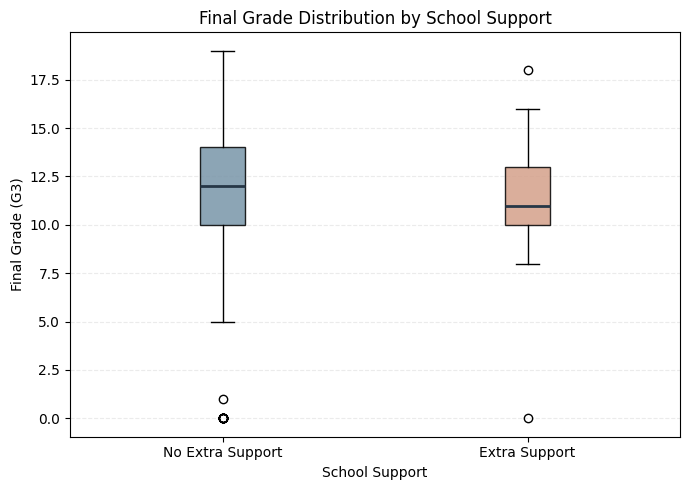

In [22]:
import matplotlib.pyplot as plt

support_groups = ["no", "yes"]

support_data = [
    df_raw.loc[df_raw["schoolsup"] == group, "G3"].dropna()
    for group in support_groups
]

colors = ["#7895A8", "#D4A08A"]

plt.figure(figsize=(7, 5))

box = plt.boxplot(
    support_data,
    patch_artist=True,
    showfliers=True
)

for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

for median in box["medians"]:
    median.set_color("#263746")
    median.set_linewidth(2)

plt.xticks(
    [1, 2],
    ["No Extra Support", "Extra Support"]
)
plt.xlabel("School Support")
plt.ylabel("Final Grade (G3)")
plt.title("Final Grade Distribution by School Support")
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()



- Students receiving extra school support have a slightly lower median final grade (11) than those without support (12).
- The grade distributions overlap, and the support group is much smaller (68 compared with 581 students).
- This difference does not mean that extra support lowers grades. Students experiencing academic difficulties may be more likely to receive support, creating potential selection bias.

The data show an association, but they do not establish whether school support improves academic performance.

#### 5.3 Social and Lifestyle Factors

So far we have looked at **academic** factors (previous grades, failures) and **study-related** factors (study time, absences, school support). Now we look at factors that describe **who the student is and the environment around them**:

- **Sex** (`sex`) and **home address** (`address`).
- **Parents' education** (`Medu`, `Fedu`).
- **Family educational support** (`famsup`) and **going out with friends** (`goout`).

We do not need to analyze every column in the dataset. We selected these because they help answer the project question: which factors are associated with final grades, and which of them can be used fairly to evaluate a student. Many of them describe a student's *circumstances* rather than their *effort or ability*, and that distinction matters in Section 7.

To avoid repeating the same code, we first define a small helper that builds the usual summary table (number of students, average and median final grade) for any column.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Soft color palette used in the previous sections
BLUE, SAGE, TERRACOTTA, LAVENDER = "#7895A8", "#A9BDB0", "#D4A08A", "#9B9BB5"
EDGE, TEXT = "#536471", "#263746"


def grade_summary(column):
    """Number of students, average and median final grade for each group."""
    summary = df_raw.groupby(column)["G3"].agg(
        ["count", "mean", "median"]
    ).round(2)
    return summary.rename(columns={
        "count": "Number of Students",
        "mean": "Average Final Grade",
        "median": "Median Final Grade"
    })



##### Sex and Home Address

We compare the final grades of female and male students, and of students living in rural (`R`) and urban (`U`) areas.

In [ ]:
print("Sex")
display(grade_summary("sex"))

print("Home address (R = rural, U = urban)")
display(grade_summary("address"))

- Female students are the larger group (**383** vs **266**) and have a higher average final grade (**12.25**) than male students (**11.41**). The median is 12 for girls and 11 for boys.
- Students living in urban areas (452 students) have a higher average (**12.26**) than students in rural areas (197 students, **11.09**).
- Both gaps are small compared with the 0 to 20 grade scale: about **0.84** points for sex and **1.17** points for address.

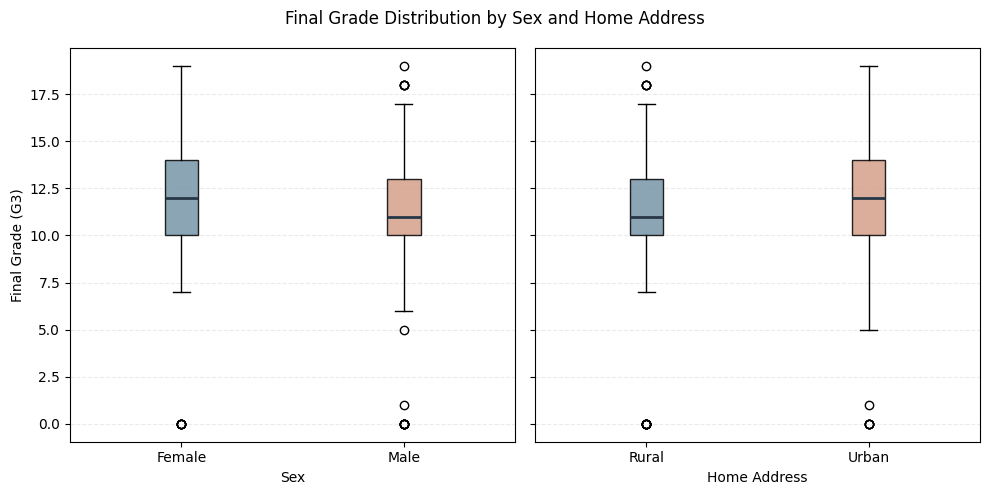

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

panels = [
    ("sex", ["F", "M"], ["Female", "Male"], "Sex"),
    ("address", ["R", "U"], ["Rural", "Urban"], "Home Address"),
]

for ax, (column, groups, labels, xlabel) in zip(axes, panels):
    data = [df_raw.loc[df_raw[column] == g, "G3"] for g in groups]
    box = ax.boxplot(data, patch_artist=True, showfliers=True)

    for patch, color in zip(box["boxes"], [BLUE, TERRACOTTA]):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)

    for median in box["medians"]:
        median.set_color(TEXT)
        median.set_linewidth(2)

    ax.set_xticks([1, 2], labels)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", linestyle="--", alpha=0.25)

axes[0].set_ylabel("Final Grade (G3)")
fig.suptitle("Final Grade Distribution by Sex and Home Address")
plt.tight_layout()
plt.savefig(FIGURES / "sex_address_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

- In both comparisons the boxes **overlap substantially**: many students in the "lower" group score as well as or better than the typical student in the "higher" group.
- The differences between group averages are real in this dataset, but they are not large enough to say anything reliable about an individual student.

**Is the address gap really about where a student lives?**

The dataset covers two schools. If rural students are concentrated in the school with lower average grades, part of the "address effect" could actually be a **school effect**. We check this by comparing the two addresses *within* each school.

In [25]:
display(
    df_raw.groupby(["school", "address"])["G3"]
    .agg(["count", "mean"])
    .round(2)
    .rename(columns={
        "count": "Number of Students",
        "mean": "Average Final Grade"
    })
)

print("Share of rural students in each school (%):")
print(
    df_raw.groupby("school")["address"]
    .apply(lambda s: (s == "R").mean() * 100)
    .round(1)
)

Number of Students  Average Final Grade
school address                                         
GP     R                        78                12.14
       U                       345                12.68
MS     R                       119                10.39
       U                       107                10.93

Share of rural students in each school (%):
school
GP    18.4
MS    52.7
Name: address, dtype: float64


- Rural students are much more common in school **MS** (**52.7%** of its students) than in school **GP** (**18.4%**), and MS has lower average grades overall.
- Inside each school the urban advantage shrinks to about **0.54** points in GP and **0.54** points in MS, roughly half of the overall gap (1.17).
- This is a good example of **confounding**: part of what looks like an effect of address is really a difference between schools. It is one reason to be careful when interpreting simple group comparisons.

##### Parents' Education (`Medu`, `Fedu`)

Parents' education is recorded on a 0 to 4 scale: **0** = none, **1** = primary education (4th grade), **2** = 5th to 9th grade, **3** = secondary education, **4** = higher education. We compare the average final grade for each level of the mother's and the father's education.

In [26]:
parent_edu = pd.DataFrame({
    "Mother: students": df_raw.groupby("Medu")["G3"].count(),
    "Mother: average G3": df_raw.groupby("Medu")["G3"].mean().round(2),
    "Father: students": df_raw.groupby("Fedu")["G3"].count(),
    "Father: average G3": df_raw.groupby("Fedu")["G3"].mean().round(2),
})
parent_edu.index.name = "Education level"
display(parent_edu)

print(f"Correlation between mother's education and G3: {df_raw['Medu'].corr(df_raw['G3']):.2f}")
print(f"Correlation between father's education and G3: {df_raw['Fedu'].corr(df_raw['G3']):.2f}")
print(f"Correlation between mother's and father's education: {df_raw['Medu'].corr(df_raw['Fedu']):.2f}")

,Mother: students,Mother: average G3,Father: students,Father: average G3
Education level,,,,
0,6,11.67,7,12.14
1,143,10.80,174,10.94
2,186,11.66,209,11.78
3,139,11.92,131,12.38
4,175,13.07,128,12.92


Correlation between mother's education and G3: 0.24
Correlation between father's education and G3: 0.21
Correlation between mother's and father's education: 0.65


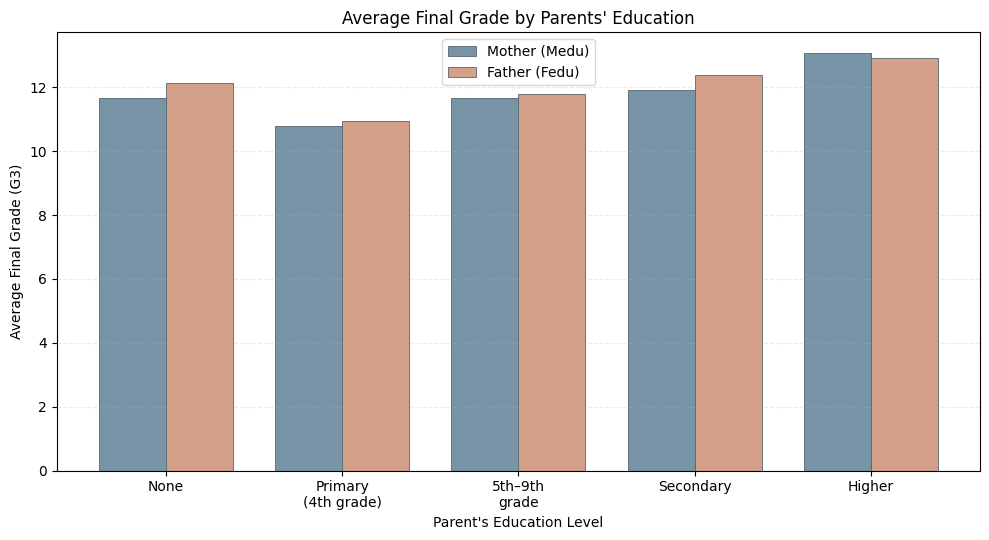

In [27]:

levels = np.arange(5)
labels = [
    "None",
    "Primary\n(4th grade)",
    "5th–9th\ngrade",
    "Secondary",
    "Higher"
]

mother = df_raw.groupby("Medu")["G3"].mean().reindex(levels)
father = df_raw.groupby("Fedu")["G3"].mean().reindex(levels)

mother_count = df_raw.groupby("Medu")["G3"].count().reindex(levels, fill_value=0)
father_count = df_raw.groupby("Fedu")["G3"].count().reindex(levels, fill_value=0)

width = 0.38

plt.figure(figsize=(10, 5.5))

plt.bar(
    levels - width / 2,
    mother.values,
    width,
    label="Mother (Medu)",
    color=BLUE,
    edgecolor=EDGE,
    linewidth=0.6
)

plt.bar(
    levels + width / 2,
    father.values,
    width,
    label="Father (Fedu)",
    color=TERRACOTTA,
    edgecolor=EDGE,
    linewidth=0.6
)

plt.xticks(levels, labels)
plt.xlabel("Parent's Education Level")
plt.ylabel("Average Final Grade (G3)")
plt.title("Average Final Grade by Parents' Education")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout()

plt.savefig(
    FIGURES / "parents_education_bars.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


- Average grades rise with the mother's education, from **10.80** (primary education) to **13.07** (higher education). The father's education shows a similar pattern, from **10.94** to **12.92**.
- The correlations are positive but modest (**0.24** for mothers, **0.21** for fathers), much weaker than the link between previous and final grades.
- Mother's and father's education are strongly related to each other (**0.65**), so they do not provide two independent pieces of information.
- Level 0 has only **6** mothers and **7** fathers, so its averages are unreliable and should not be interpreted.
- A student cannot choose their parents' education, so this association describes the student's background, not their effort or ability.

##### Family Educational Support (`famsup`) and Going Out with Friends (`goout`)

`famsup` records whether the family provides educational support, and `goout` records how often the student goes out with friends, from **1** (very low) to **5** (very high). Both come from student questionnaires, so they are **self-reported**.

In [28]:
print("Family educational support")
display(grade_summary("famsup"))

famsup_by_medu = (
    df_raw.groupby("Medu")["famsup"]
    .apply(lambda s: (s == "yes").mean() * 100)
    .round(1)
    .rename("Students with family support (%)")
)
print("Family support by mother's education:")
display(famsup_by_medu.to_frame())

Family educational support


,Number of Students,Average Final Grade,Median Final Grade
famsup,,,
no,251,11.67,12.0
yes,398,12.06,12.0


Family support by mother's education:


,Students with family support (%)
Medu,
0,50.0
1,55.2
2,56.5
3,64.0
4,69.7


- Students with family educational support have a slightly higher average final grade (**12.06**) than those without it (**11.67**), and the median is the same (**12**) in both groups. The difference is only about **0.39** points.
- Family support is more common when the mother has more education (**55.2%** at level 1 vs **69.7%** at level 4), so `famsup` is partly connected to family background and not an independent factor.
- This is a weak association and should not be read as "family support raises grades".

Going out with friends (1 = very low, 5 = very high)


,Number of Students,Average Final Grade,Median Final Grade
goout,,,
1,48,10.73,11.0
2,145,12.67,13.0
3,205,12.15,12.0
4,141,11.97,12.0
5,110,10.87,11.0


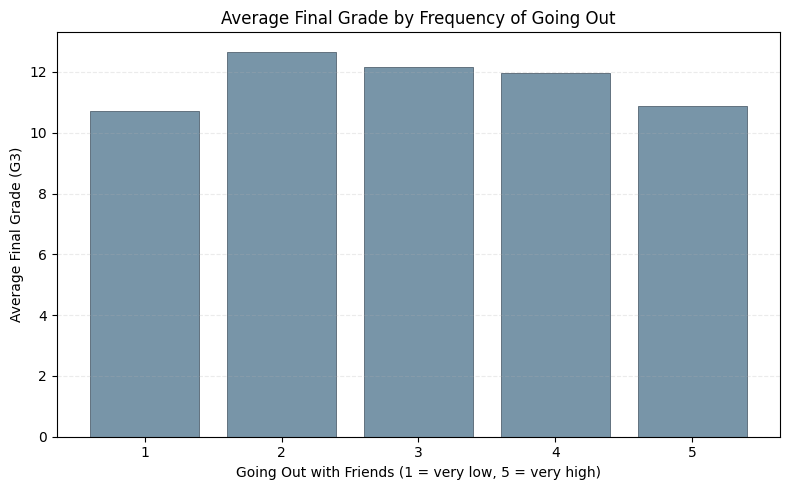

Correlation between going out and G3: -0.09


In [29]:
print("Going out with friends (1 = very low, 5 = very high)")
display(grade_summary("goout"))

goout_means = df_raw.groupby("goout")["G3"].mean()

plt.figure(figsize=(8, 5))
plt.bar(
    goout_means.index,
    goout_means.values,
    color=BLUE,
    edgecolor=EDGE,
    linewidth=0.6
)

plt.xlabel("Going Out with Friends (1 = very low, 5 = very high)")
plt.ylabel("Average Final Grade (G3)")
plt.title("Average Final Grade by Frequency of Going Out")
plt.xticks(range(1, 6))
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES / "goout_average_grade.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Correlation between going out and G3: {df_raw['goout'].corr(df_raw['G3']):.2f}")

- The pattern is **not a straight line**. Students who go out a moderate amount (levels 2 to 4) have the highest averages, with a peak of **12.67** at level 2. Both the lowest level (48 students, **10.73**) and the highest level (110 students, **10.87**) have lower averages.
- Because the pattern is curved, the overall correlation (**-0.09**) is close to zero and hides it.
- The data cannot tell us why. Students who rarely go out might be isolated or have other responsibilities, and students who go out very often might spend less time studying. These are only hypotheses.

##### Comparing Students with Similar Previous Grades

To investigate whether social and demographic characteristics are associated with final grades beyond previous academic performance, we compare students within similar `G2` grade ranges. This helps us examine whether differences between groups remain when their earlier grades are comparable.

In [30]:
comparison_df = df_raw.copy()

comparison_df["G2_band"] = pd.cut(
    comparison_df["G2"],
    bins=[-1, 9, 11, 13, 20],
    labels=["Below 10", "10–11", "12–13", "14+"]
)

comparison_df["parent_education"] = comparison_df["Medu"].map({
    0: "Below secondary/none",
    1: "Below secondary/none",
    2: "Below secondary/none",
    3: "Secondary or higher",
    4: "Secondary or higher"
})

def compare_groups(group_column):
    result = (
        comparison_df
        .groupby(["G2_band", group_column], observed=True)["G3"]
        .agg(
            n="count",
            mean_G3="mean",
            median_G3="median"
        )
        .round(2)
    )
    display(result)

print("Final grades by sex within G2 groups:")
compare_groups("sex")

print("Final grades by address within G2 groups:")
compare_groups("address")

print("Final grades by mother's education within G2 groups:")
compare_groups("parent_education")

Final grades by sex within G2 groups:


n  mean_G3  median_G3
G2_band  sex                         
Below 10 F     72     8.08        9.0
         M     73     8.05        9.0
10–11    F    104    10.94       11.0
         M     82    10.66       11.0
12–13    F    106    12.97       13.0
         M     60    12.87       13.0
14+      F    101    15.82       16.0
         M     51    15.69       16.0

Final grades by address within G2 groups:


n  mean_G3  median_G3
G2_band  address                         
Below 10 R         59     7.53        9.0
         U         86     8.44        9.0
10–11    R         70    10.83       11.0
         U        116    10.81       11.0
12–13    R         30    12.80       13.0
         U        136    12.96       13.0
14+      R         38    15.74       15.0
         U        114    15.79       16.0

Final grades by mother's education within G2 groups:


n  mean_G3  median_G3
G2_band  parent_education                             
Below 10 Below secondary/none   90     8.04        9.0
         Secondary or higher    55     8.11        9.0
10–11    Below secondary/none  114    10.82       11.0
         Secondary or higher    72    10.82       11.0
12–13    Below secondary/none   81    12.89       13.0
         Secondary or higher    85    12.98       13.0
14+      Below secondary/none   50    15.64       15.0
         Secondary or higher   102    15.84       16.0

In [31]:
# Compare rural and urban students with G2 < 10,
# before and after excluding zero final grades

low_g2 = df_raw[df_raw["G2"] < 10]

print("All students with G2 < 10:")
display(
    low_g2.groupby("address")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

low_g2_nonzero = low_g2[low_g2["G3"] != 0]

print("Students with G2 < 10 and G3 != 0:")
display(
    low_g2_nonzero.groupby("address")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

All students with G2 < 10:


,count,mean,median
address,,,
R,59,7.53,9.0
U,86,8.44,9.0


Students with G2 < 10 and G3 != 0:


,count,mean,median
address,,,
R,49,9.06,9.0
U,81,8.96,9.0




Among students with `G2 < 10`, rural students initially have a lower average final grade than urban students (7.53 vs. 8.44). However, after excluding students with `G3 = 0`, the averages become very similar (9.06 for rural students and 8.96 for urban students).

This suggests that the initial gap is largely associated with the zero-grade cases rather than a consistent difference between rural and urban students in this group. However, the reasons for the zero grades remain unknown, so this result should be interpreted cautiously.

**Key Findings**

- **Sex:** Girls and boys have very similar average final grades when compared within the same `G2` grade groups.
- **Mother's education:** Differences in average final grades are small across all `G2` groups.
- **Address:** The initial rural–urban gap among students with `G2 < 10` largely disappears when students with `G3 = 0` are excluded (9.06 for rural students vs. 8.96 for urban students).

These findings suggest that some group differences become smaller when previous grades and zero-grade cases are examined. However, these comparisons do not prove that background characteristics have no additional predictive value or that previous grades are free from bias.


**Summary of Section 5.3**

Social and lifestyle factors show weaker associations with final grades than previous academic performance. Comparisons within similar `G2` groups reveal very small differences by sex and mother's education, while the rural–urban difference in the lowest `G2` group is largely explained by the zero-grade cases.

These findings highlight the importance of examining group differences carefully and avoiding assumptions about an individual's ability or potential based on their background.

### 6. Ethical Considerations and Limitations

Finding that a factor is associated with grades does not mean it should be used to evaluate a student. We need to ask two different questions:

1. **How strongly** is the factor associated with the final grade?
2. **Is it fair** to use it to judge a student, given that the student may not control it and that it may reflect disadvantage rather than ability?

We start with the first question. For each factor we compare the strength of its association with the final grade `G3` (absolute value of the correlation; binary factors are coded as 0/1).

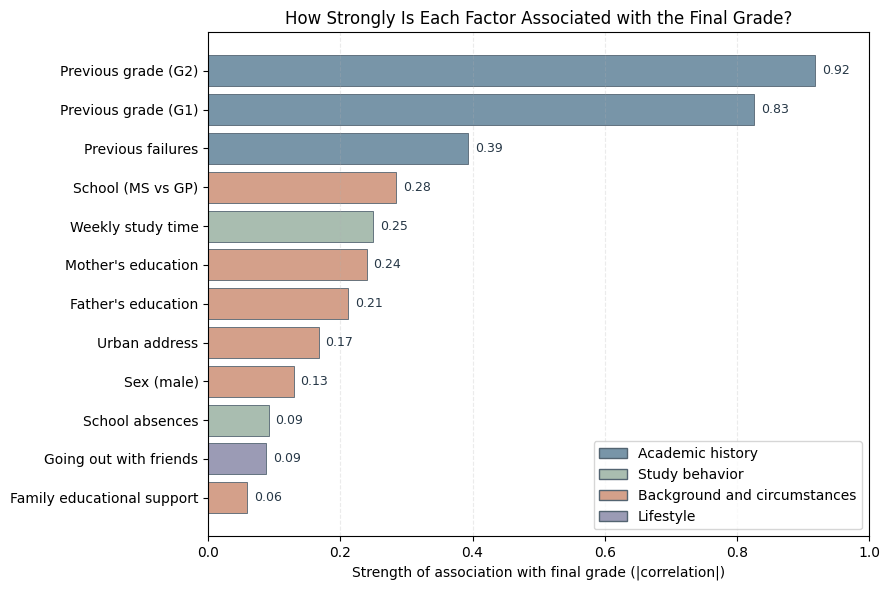

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Same soft color palette
BLUE, SAGE, TERRACOTTA, LAVENDER = "#7895A8", "#A9BDB0", "#D4A08A", "#9B9BB5"
EDGE, TEXT = "#536471", "#263746"

encoded = pd.DataFrame({
    "Previous grade (G2)": df_raw["G2"],
    "Previous grade (G1)": df_raw["G1"],
    "Previous failures": df_raw["failures"],
    "Weekly study time": df_raw["studytime"],
    "School absences": df_raw["absences"],
    "School (MS vs GP)": (df_raw["school"] == "MS").astype(int),
    "Mother's education": df_raw["Medu"],
    "Father's education": df_raw["Fedu"],
    "Urban address": (df_raw["address"] == "U").astype(int),
    "Sex (male)": (df_raw["sex"] == "M").astype(int),
    "Family educational support": (df_raw["famsup"] == "yes").astype(int),
    "Going out with friends": df_raw["goout"],
})

category = {
    "Previous grade (G2)": "Academic history",
    "Previous grade (G1)": "Academic history",
    "Previous failures": "Academic history",
    "Weekly study time": "Study behavior",
    "School absences": "Study behavior",
    "School (MS vs GP)": "Background and circumstances",
    "Mother's education": "Background and circumstances",
    "Father's education": "Background and circumstances",
    "Urban address": "Background and circumstances",
    "Sex (male)": "Background and circumstances",
    "Family educational support": "Background and circumstances",
    "Going out with friends": "Lifestyle",
}
category_colors = {
    "Academic history": BLUE,
    "Study behavior": SAGE,
    "Background and circumstances": TERRACOTTA,
    "Lifestyle": LAVENDER,
}

strength = encoded.corrwith(df_raw["G3"]).abs().sort_values()

plt.figure(figsize=(9, 6))
plt.barh(
    strength.index,
    strength.values,
    color=[category_colors[category[name]] for name in strength.index],
    edgecolor=EDGE,
    linewidth=0.6
)

for position, value in enumerate(strength.values):
    plt.text(value + 0.01, position, f"{value:.2f}", va="center",
             color=TEXT, fontsize=9)

plt.xlim(0, 1)
plt.xlabel("Strength of association with final grade (|correlation|)")
plt.title("How Strongly Is Each Factor Associated with the Final Grade?")
plt.legend(
    handles=[Patch(facecolor=color, edgecolor=EDGE, label=name)
             for name, color in category_colors.items()],
    loc="lower right"
)
plt.grid(axis="x", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES / "association_strength.png", dpi=150, bbox_inches="tight")
plt.show()

- **Previous grades dominate**: `G2` (**0.92**) and `G1` (**0.83**) are far stronger than anything else. This mostly shows that performance is **consistent over time**, not that earlier grades determine a student's future.
- The next strongest are previous failures (**0.39**), the school (**0.28**) and weekly study time (**0.25**).
- Background factors such as sex (**0.13**), address (**0.17**) and family support (**0.06**) are weak. Parents' education (0.24 and 0.21) is the strongest of them, but still far below prior grades.
- Even the strongest background factor says very little about an individual student compared with their own grade history.

**Do group averages describe individual students?**

Differences between group averages do not determine an individual student's performance. Students within the same demographic group can have very different grades, so group-level patterns should not be used to assume an individual's ability or potential.

In [33]:
girls_avg = df_raw.loc[df_raw["sex"] == "F", "G3"].mean()
boys = df_raw.loc[df_raw["sex"] == "M", "G3"]

urban_avg = df_raw.loc[df_raw["address"] == "U", "G3"].mean()
rural = df_raw.loc[df_raw["address"] == "R", "G3"]

print(f"Average girl: {girls_avg:.2f} | "
      f"boys scoring above it: {(boys > girls_avg).mean() * 100:.1f}%")
print(f"Average urban student: {urban_avg:.2f} | "
      f"rural students scoring above it: {(rural > urban_avg).mean() * 100:.1f}%")

Average girl: 12.25 | boys scoring above it: 35.0%
Average urban student: 12.26 | rural students scoring above it: 29.9%


- About **35.0%** of male students score above the average female student, and about **29.9%** of rural students score above the average urban student.
- Judging a student by the average of their group would therefore be wrong for a large share of students. **The group is not the individual.**

**Which Factors Should and Should Not Be Used to Evaluate Students?**

| Factor | Appropriate Use | Ethical Concern |
|---|---|---|
| Previous grades and failures | Identify current learning needs and offer support. | Past results should not define a student's permanent ability or potential. |
| Study time and absences | Explore possible barriers and discuss support needs. | The data do not explain circumstances such as health, family responsibilities, or transport. |
| Gender, address, school, and parents' education | Examine inequalities and differences in access to resources at group level. | Using these characteristics to rank individual students may reinforce disadvantage or discrimination. |
| Family support and lifestyle | Explore context cautiously when relevant. | These variables may be self-reported, private, and insufficient to assess ability. |

The appropriate use of a factor depends on the decision being made. Information that helps identify unequal access to support should not automatically become a criterion for ranking or labelling individual students.

### Limitations of This Analysis

- **Association is not causation.** The observed relationships do not prove cause and effect. For example, the difference in grades between urban and rural students becomes smaller when comparing students within the same school. Comparisons of school support may also be affected by differences between students receiving support and those who do not.

- **Small groups.** Some groups contain very few students, such as the six students whose mothers have no formal education. Their averages may be unstable and should be interpreted cautiously.

- **Ambiguous zero grades.** Fifteen students have a final grade of zero. All 15 have zero recorded absences, 14 attend school MS, and seven also have a zero in G2. The dataset does not explain why these grades occurred, so we cannot determine whether they represent ordinary low performance or other circumstances.

- **Limited sample.** The data come from two secondary schools in Portugal and focus only on Portuguese-language grades. The findings may not generalize to other schools, subjects, countries, or periods.

- **Self-reported information.** Variables such as `goout` and `famsup` are based on questionnaires and may contain inaccuracies or reflect differences in how students interpret the questions.

- **Limited measure of performance.** The final grade (`G3`) measures academic performance in one subject. It does not fully capture a student's effort, progress, ability, or future potential.

- **Potential proxies for disadvantage.** Variables such as home address and parents' education may reflect broader socioeconomic circumstances. Using them to rank or label individual students could reinforce existing inequalities rather than fairly assess their ability or potential.

 ### 7. Main Finding and Conclusion

### What Is Associated with Final Grades?

Previous academic grades show the strongest associations with final performance: `G2` has a correlation of **0.92** with `G3`, and `G1` has a correlation of **0.83**. Since these are grades from the same academic year, they mainly reflect continuity in performance over time.

Previous failures are also associated with lower final grades. Students with no previous failures have an average of **12.51**, compared with **8.07–8.81** among students with previous failures. Study time shows a positive association with grades up to the 5–10 hours category, while the relationship between absences and final grades is weak and sensitive to how zero-grade cases are handled.

### Which Factors Should Not Be Used to Judge a Student?

When students with similar previous grades are compared, differences by sex and mother's education become very small. Differences by home address are also small in most grade groups, although the lowest-grade group requires further investigation.

Social and demographic characteristics should not automatically be used to rank or label individual students. These variables may help identify inequalities between groups, but they are not direct measures of individual ability or potential.

Previous grades can help identify students who may need support, but they should not be treated as fixed measures of future potential. Earlier grades may also reflect existing inequalities or previous difficulties.

### Conclusion

The analysis shows that previous academic performance is strongly associated with final grades, while study habits and previous failures also reveal meaningful patterns. Comparisons within similar previous-grade groups suggest that several social and demographic differences become much smaller.

The central message is that **student data should be used to understand learning needs and improve support, not to label students or limit their opportunities**. Group-level statistics can help identify inequalities, but they do not define individual students.

These findings are descriptive, not causal. They are also limited to Portuguese-language grades from two Portuguese secondary schools in the mid-2000s and should not automatically be generalized to other educational settings.